In [1]:
# BigMart Sales: EDA
#
# Goal: predict Item_Outlet_Sales for every (product, store) pair. We have 8523 rows with
# sales (train) and 5681 without (test).
# The score is RMSE, so a smaller number is better.
#
# This notebook looks at the data first, then tests two simple ideas: Pearson correlation
# and a t-test.

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# 1. First look

df = pd.read_csv("../dataset/train_v9rqX0R.csv")

def counts_table(col):
    # count and percent of every value in a column (missing values included)
    return pd.DataFrame({'count': col.value_counts(dropna=False),
                         'percent': (col.value_counts(dropna=False, normalize=True) * 100).round(2)})

def missing_table(data):
    return pd.DataFrame({'missing': data.isnull().sum(),
                         'percent': (data.isnull().mean() * 100).round(2)})

In [3]:
df.shape

(8523, 12)

In [4]:
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


In [6]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [7]:
missing_table(df)

# Two columns have missing values: Item_Weight (1463, 17.17%) and Outlet_Size (2410,
# 28.28%). We will not use them to predict sales, so we only fill them to keep the data
# tidy.

,missing,percent
Item_Identifier,0,0.00
Item_Weight,1463,17.17
Item_Fat_Content,0,0.00
Item_Visibility,0,0.00
Item_Type,0,0.00
Item_MRP,0,0.00
Outlet_Identifier,0,0.00
Outlet_Establishment_Year,0,0.00
Outlet_Size,2410,28.28
Outlet_Location_Type,0,0.00


In [8]:
# Outlet_Size before it is filled: the NaN row shows the missing share
counts_table(df['Outlet_Size'])

,count,percent
Outlet_Size,,
Medium,2793,32.77
NaN,2410,28.28
Small,2388,28.02
High,932,10.94


In [9]:
# 2. Cleaning

counts_table(df['Item_Fat_Content'])

,count,percent
Item_Fat_Content,,
Low Fat,5089,59.71
Regular,2889,33.90
LF,316,3.71
reg,117,1.37
low fat,112,1.31


In [10]:
# The same two labels are written in different ways (LF, low fat, reg). We make them
# consistent.

df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})
counts_table(df['Item_Fat_Content'])

,count,percent
Item_Fat_Content,,
Low Fat,5517,64.73
Regular,3006,35.27


In [11]:
df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Weight'].mean())
df['Outlet_Size'] = df['Outlet_Size'].fillna(df['Outlet_Size'].mode()[0])
missing_table(df)

,missing,percent
Item_Identifier,0,0.0
Item_Weight,0,0.0
Item_Fat_Content,0,0.0
Item_Visibility,0,0.0
Item_Type,0,0.0
Item_MRP,0,0.0
Outlet_Identifier,0,0.0
Outlet_Establishment_Year,0,0.0
Outlet_Size,0,0.0
Outlet_Location_Type,0,0.0


In [12]:
zeros = (df['Item_Visibility'] == 0).sum()
print('rows with visibility 0:', zeros, '(', round(zeros / len(df) * 100, 2), '% )')

# 526 items (6.17% of rows) have visibility 0, which is not possible for an item on a shelf.
# We note it but do not use this column.

rows with visibility 0: 526 ( 6.17 % )


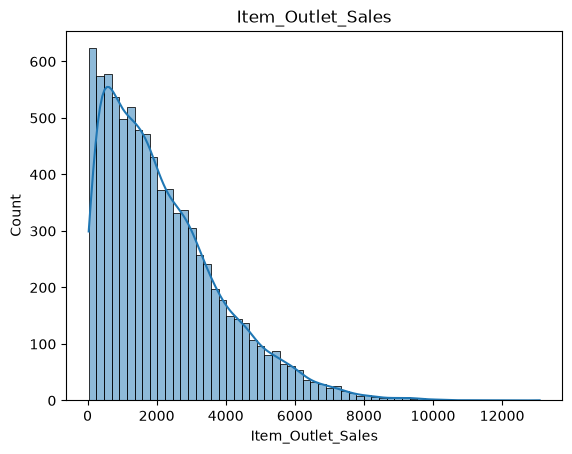

In [13]:
# 3. One column at a time

sns.histplot(df['Item_Outlet_Sales'], kde=True)
plt.title('Item_Outlet_Sales')
plt.savefig('../outputs/figures/sales_histogram.png', dpi=120, bbox_inches='tight')
plt.show()

# Most sales are small and a few are very large, so the histogram is skewed to the right.

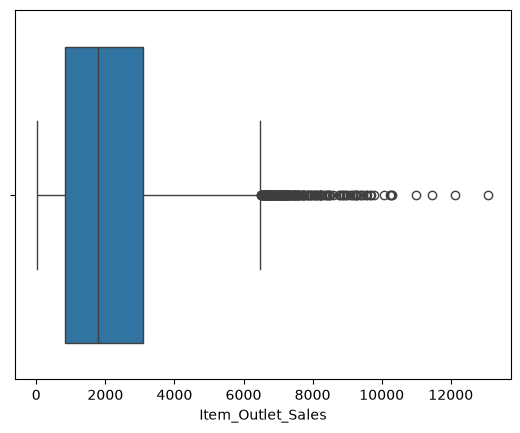

In [14]:
sns.boxplot(x=df['Item_Outlet_Sales'])
plt.show()

In [15]:
for col in ['Item_Outlet_Sales', 'Item_MRP']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print('---', col, '---')
    print('Lower Bound:', lower_bound)
    print('Upper Bound:', upper_bound)
    print('Number of outliers:', len(outliers), '(', round(len(outliers) / len(df) * 100, 2), '% of rows )')
    print()

# Sales has 186 outliers (2.18% of rows), all on the high side. They are real big sales, not
# mistakes, so we keep them (removing them would make the model worse on exactly the rows
# that cost the most RMSE). MRP has none.

--- Item_Outlet_Sales ---
Lower Bound: -2566.3261
Upper Bound: 6501.8699
Number of outliers: 186 ( 2.18 % of rows )

--- Item_MRP ---
Lower Bound: -43.8993
Upper Bound: 323.3695
Number of outliers: 0 ( 0.0 % of rows )



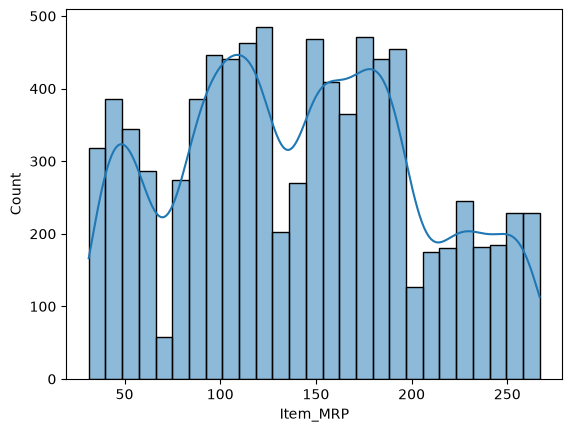

In [16]:
sns.histplot(df['Item_MRP'], kde=True)
plt.show()

In [17]:
counts_table(df['Outlet_Type'])

,count,percent
Outlet_Type,,
Supermarket Type1,5577,65.43
Grocery Store,1083,12.71
Supermarket Type3,935,10.97
Supermarket Type2,928,10.89


In [18]:
for col in ['Outlet_Identifier', 'Outlet_Location_Type', 'Item_Type']:
    print(col)
    print(counts_table(df[col]))
    print()

Outlet_Identifier
                   count  percent
Outlet_Identifier                
OUT027               935    10.97
OUT013               932    10.94
OUT049               930    10.91
OUT046               930    10.91
OUT035               930    10.91
OUT045               929    10.90
OUT018               928    10.89
OUT017               926    10.86
OUT010               555     6.51
OUT019               528     6.20

Outlet_Location_Type
                      count  percent
Outlet_Location_Type                
Tier 3                 3350    39.31
Tier 2                 2785    32.68
Tier 1                 2388    28.02

Item_Type
                       count  percent
Item_Type                            
Fruits and Vegetables   1232    14.46
Snack Foods             1200    14.08
Household                910    10.68
Frozen Foods             856    10.04
Dairy                    682     8.00
Canned                   649     7.61
Baking Goods             648     7.60
Health and Hyg

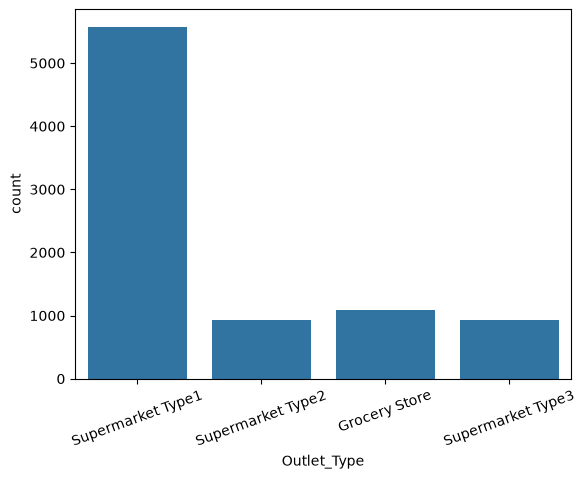

In [19]:
sns.countplot(x='Outlet_Type', data=df)
plt.xticks(rotation=20)
plt.show()

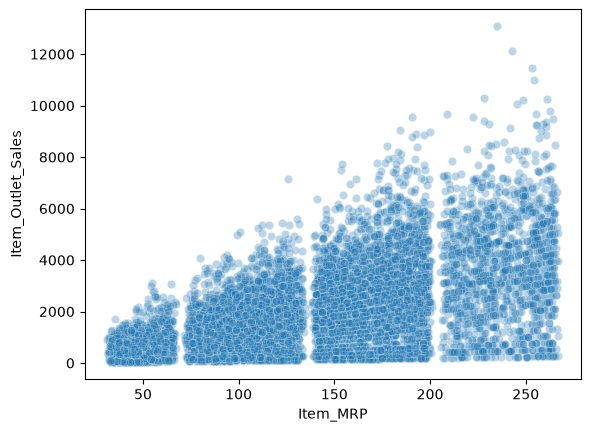

In [20]:
# 4. Sales against other columns

sns.scatterplot(x='Item_MRP', y='Item_Outlet_Sales', data=df, alpha=0.3)
plt.savefig('../outputs/figures/sales_vs_mrp.png', dpi=120, bbox_inches='tight')
plt.show()

# Dearer items sell for more money. The points fan out as the price grows.

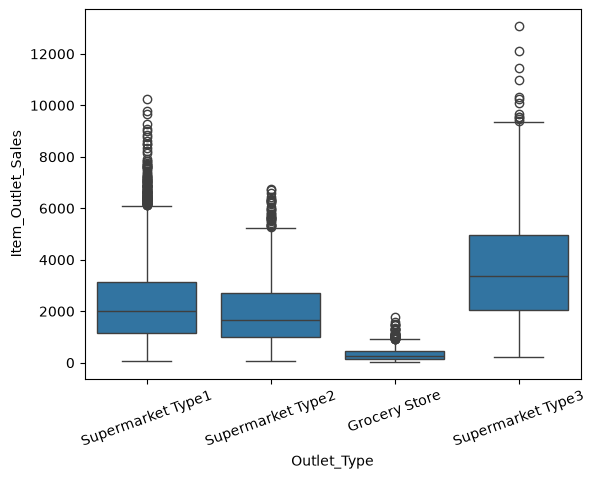

In [21]:
sns.boxplot(x='Outlet_Type', y='Item_Outlet_Sales', data=df)
plt.xticks(rotation=20)
plt.savefig('../outputs/figures/sales_by_outlet_type.png', dpi=120, bbox_inches='tight')
plt.show()

In [22]:
df.groupby('Outlet_Type')['Item_Outlet_Sales'].mean()

# Grocery stores sell far less than supermarkets, and Supermarket Type3 sells the most.

Outlet_Type
Grocery Store         339.828500
Supermarket Type1    2316.181148
Supermarket Type2    1995.498739
Supermarket Type3    3694.038558
Name: Item_Outlet_Sales, dtype: float64

In [23]:
df.groupby('Outlet_Identifier')['Item_Outlet_Sales'].mean()

Outlet_Identifier
OUT010     339.351662
OUT013    2298.995256
OUT017    2340.675263
OUT018    1995.498739
OUT019     340.329723
OUT027    3694.038558
OUT035    2438.841866
OUT045    2192.384798
OUT046    2277.844267
OUT049    2348.354635
Name: Item_Outlet_Sales, dtype: float64

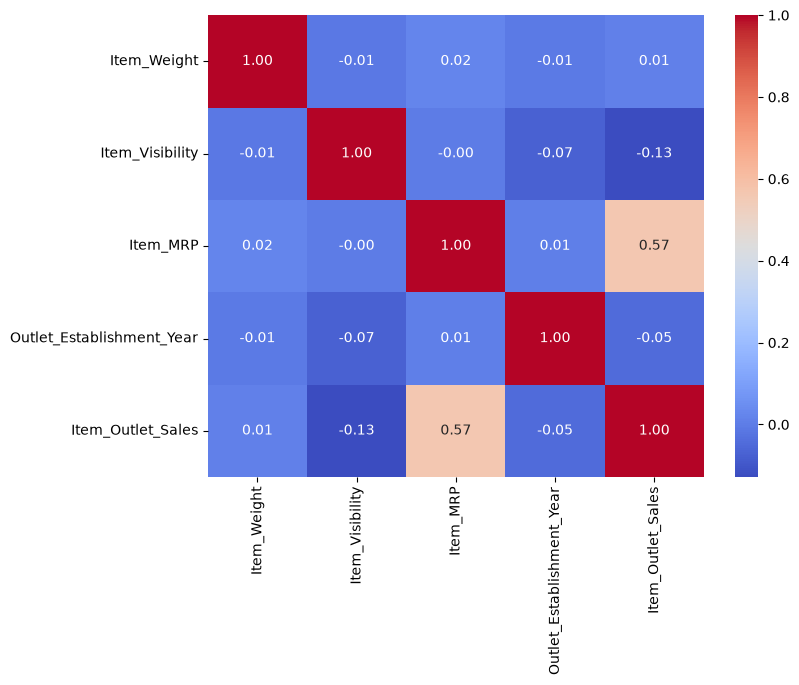

In [24]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

# The only column with a clear link to sales is Item_MRP.

In [25]:
# 5. Pearson correlation
#
# Pearson's r measures how straight-line the link between two numbers is. It goes from -1 to
# +1, and 0 means no linear link.
#
# - H0: there is no linear relationship between the two columns.
# - H1: there is a linear relationship.
# - If the p-value is below 0.05 we reject H0.

for col in ['Item_MRP', 'Item_Weight', 'Item_Visibility', 'Outlet_Establishment_Year']:
    r, p = stats.pearsonr(df[col], df['Item_Outlet_Sales'])
    print(f"{col:28s} r = {r:6.3f}   p-value = {p:.4f}")

# - Item_MRP: r is about 0.57 with a tiny p-value, so there is a clear positive link. This
#     is the column to build the model on.
# - Item_Visibility has a small negative r. The average visibility is 0.105 in grocery
#     stores against about 0.06 in supermarkets, and grocery stores sell less, so this link
#     mostly comes from the store type.
# - Item_Weight has r close to 0 and a large p-value (0.29), so we cannot say it is linked
#     to sales.
# - Outlet_Establishment_Year has a tiny p-value but r is only -0.05. The link is real but
#     far too weak to help.

Item_MRP                     r =  0.568   p-value = 0.0000
Item_Weight                  r =  0.012   p-value = 0.2863
Item_Visibility              r = -0.129   p-value = 0.0000
Outlet_Establishment_Year    r = -0.049   p-value = 0.0000


In [26]:
# 6. A basic test: do grocery stores really sell less?
#
# We compare the average sales of grocery stores with Supermarket Type1 using a two-sample
# t-test.
#
# - H0: both store types have the same average sales.
# - H1: the averages are different.

grocery = df[df['Outlet_Type'] == 'Grocery Store']['Item_Outlet_Sales']
super1 = df[df['Outlet_Type'] == 'Supermarket Type1']['Item_Outlet_Sales']

print('Grocery mean:', grocery.mean())
print('Supermarket Type1 mean:', super1.mean())

t, p = stats.ttest_ind(grocery, super1)
print('t =', t, ' p-value =', p)

# The p-value is far below 0.05, so we reject H0: grocery stores really do sell less. So the
# model must treat every outlet separately.

Grocery mean: 339.8285004616805
Supermarket Type1 mean: 2316.181148108302
t = -42.777859363653086  p-value = 0.0


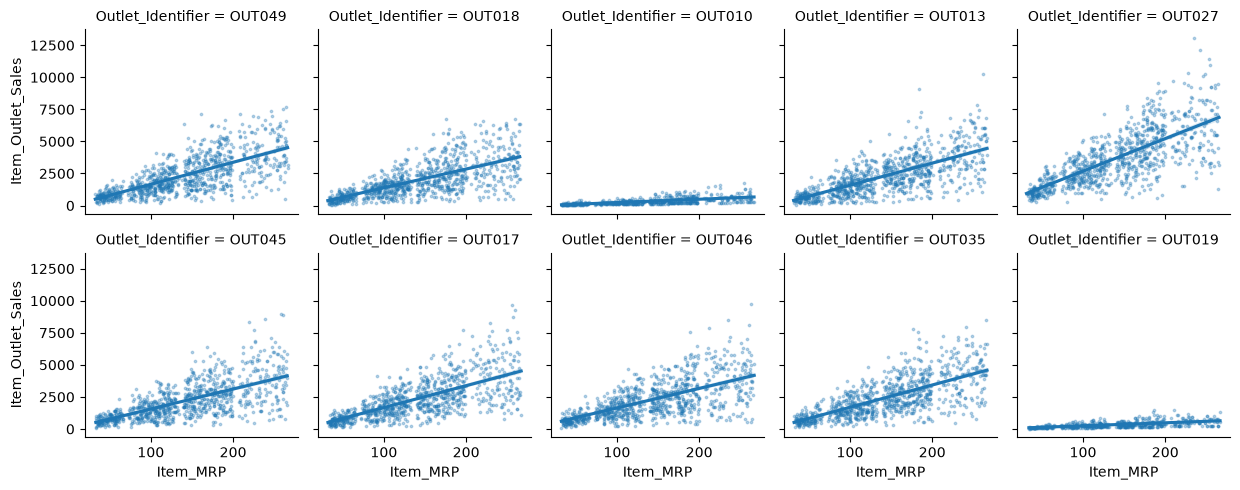

In [27]:
# 7. One line per outlet
#
# Inside one outlet, sales rise in a straight line with Item_MRP. The picture below shows
# one line per outlet.

sns.lmplot(x='Item_MRP', y='Item_Outlet_Sales', col='Outlet_Identifier', col_wrap=5, data=df,
           scatter_kws={'s': 3, 'alpha': 0.3}, height=2.5)
plt.savefig('../outputs/figures/line_per_outlet.png', dpi=120, bbox_inches='tight')
plt.show()

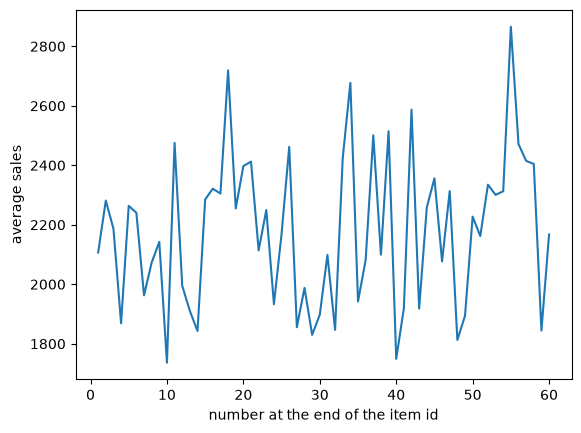

In [28]:
# The id of every item ends in a number (FDA15 has 15). The average sales for each number is
# not flat, so the number carries a little information.

df['id_num'] = df['Item_Identifier'].str[3:].astype(int)
df.groupby('id_num')['Item_Outlet_Sales'].mean().plot()
plt.xlabel('number at the end of the item id')
plt.ylabel('average sales')
plt.savefig('../outputs/figures/sales_by_id_number.png', dpi=120, bbox_inches='tight')
plt.show()

In [29]:
# 8. A quick model
#
# We split the data into 80% to learn from and 20% to check, and compare two models by RMSE:
#
# 1. the same prediction (the average sales) for every row,
# 2. one straight line of sales on Item_MRP per outlet.

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

tr, va = train_test_split(df, test_size=0.2, random_state=42)

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

# model 1: the average for everyone
print('Average only:', rmse(va['Item_Outlet_Sales'], tr['Item_Outlet_Sales'].mean()))

# model 2: one line per outlet
va = va.copy()
va['pred'] = 0.0
for outlet in tr['Outlet_Identifier'].unique():
    a = tr[tr['Outlet_Identifier'] == outlet]
    b = va['Outlet_Identifier'] == outlet
    line = LinearRegression().fit(a[['Item_MRP']], a['Item_Outlet_Sales'])
    va.loc[b, 'pred'] = line.predict(va.loc[b, ['Item_MRP']])

print('Line per outlet:', rmse(va['Item_Outlet_Sales'], va['pred']))

Average only: 1651.989750472933
Line per outlet: 1014.7638762142487


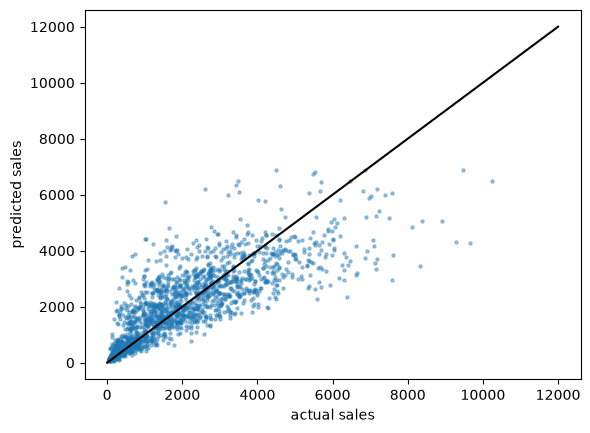

In [30]:
plt.scatter(va['Item_Outlet_Sales'], va['pred'], s=5, alpha=0.4)
plt.plot([0, 12000], [0, 12000], color='black')
plt.xlabel('actual sales')
plt.ylabel('predicted sales')
plt.savefig('../outputs/figures/actual_vs_predicted.png', dpi=120, bbox_inches='tight')
plt.show()

# The points follow the black line but spread out for big sales, which is why the RMSE stays
# large (about 1000 here, against 1650 for the plain average). Much of the sales is simply
# random.
#
# The final solution (solutions/solution_v5.py) goes further: it uses a cleaner price and
# the id number, as the next sections show.

In [31]:
# 9. A hidden pattern: sales are whole units times a price
#
# The scatter of sales against Item_MRP fans out a lot. Maybe that is not pure randomness. A
# sale is money, and money comes from selling a whole number of units at a price. If every
# sale is units × price, then every sales value should be a whole multiple of some small
# step.
#
# The step that works is 0.6658. Dividing sales by it should give whole numbers.

STEP = 0.6658
df['steps'] = df['Item_Outlet_Sales'] / STEP

# how far is each value from a whole number?
gap = (df['steps'] - df['steps'].round()).abs()
print('largest gap from a whole number:', gap.max())
print('rows within 0.01 of a whole number:', (gap < 0.01).mean())

# Every one of the 8523 sales is a whole multiple of 0.6658. This is not a coincidence, so
# sales really are units × price.
#
# Now look at one item sold in 8 outlets. Its Item_MRP changes from row to row, but its
# sales do not move freely: they are 5610, 8976, 9724 ... steps.

largest gap from a whole number: 3.637978807091713e-12
rows within 0.01 of a whole number: 1.0


In [32]:
df[df['Item_Identifier'] == 'FDA15'][['Outlet_Identifier', 'Item_MRP', 'Item_Outlet_Sales', 'steps']]

,Outlet_Identifier,Item_MRP,Item_Outlet_Sales,steps
0,OUT049,249.8092,3735.1380,5610.0
831,OUT045,250.2092,5976.2208,8976.0
2599,OUT035,248.5092,6474.2392,9724.0
2643,OUT018,249.6092,5976.2208,8976.0
4874,OUT010,248.9092,498.0184,748.0
5413,OUT013,250.6092,6474.2392,9724.0
6696,OUT027,249.5092,6474.2392,9724.0
7543,OUT017,248.8092,5976.2208,8976.0


In [33]:
# The MRP of FDA15 wanders between 248.5 and 250.6, but an item has only one real price. So
# Item_MRP looks like the real price plus a small random error. We can find the real price:
# it must be a price on the 0.6658 grid, within 2 of every MRP of the item, and it must
# divide every one of the item's sales steps exactly.
#
# We recover prices from the learning part only (tr, the 80% from section 8), then check
# them.

def item_prices(d, noise=2.0):
    prices = {}
    for item, g in d.groupby('Item_Identifier'):
        k = np.round(g['Item_Outlet_Sales'] / STEP).astype(int).to_numpy()
        lo = max(int(np.ceil((g['Item_MRP'].max() - noise) / STEP)), 1)
        hi = int(np.floor((g['Item_MRP'].min() + noise) / STEP))
        fits = [q for q in range(lo, hi + 1) if np.all(k % q == 0)]
        if fits:   # if several fit, take the one nearest the average MRP
            prices[item] = min(fits, key=lambda q: abs(q * STEP - g['Item_MRP'].mean())) * STEP
    return prices

prices = item_prices(tr)
print('items with a recovered price:', len(prices), 'of', tr['Item_Identifier'].nunique())
print('validation rows whose item has a price:', va['Item_Identifier'].isin(prices).mean())

error = tr['Item_MRP'] - tr['Item_Identifier'].map(prices)
print(error.describe())

# The error MRP - real price runs from -2 to +2 with a mean of 0, like random noise. So
# Item_MRP is a noisy copy of a hidden price, and about 96% of the validation rows belong to
# an item whose price we recovered.
#
# Does the cleaner price help the line from section 8? We repeat the same line per outlet,
# once with Item_MRP and once with the recovered price.

items with a recovered price: 1479 of 1555
validation rows whose item has a price: 0.9577712609970674
count    6.447000e+03
mean     2.745463e-03
std      1.186454e+00
min     -2.000000e+00
25%     -1.000000e+00
50%      7.105427e-15
75%      1.100000e+00
max      2.000000e+00
dtype: float64


In [34]:
def line_per_outlet(price_of):
    pred = pd.Series(0.0, index=va.index)
    for outlet in tr['Outlet_Identifier'].unique():
        a = tr[tr['Outlet_Identifier'] == outlet]
        b = va['Outlet_Identifier'] == outlet
        line = LinearRegression().fit(price_of(a).to_frame('price'), a['Item_Outlet_Sales'])
        pred[b] = line.predict(price_of(va[b]).to_frame('price'))
    return rmse(va['Item_Outlet_Sales'], pred)

real_price = lambda d: d['Item_Identifier'].map(prices).fillna(d['Item_MRP'])

print('with Item_MRP:   ', line_per_outlet(lambda d: d['Item_MRP']))
print('with real price: ', line_per_outlet(real_price))

# The two numbers are almost the same. A straight line cannot use the pattern: the noise in
# MRP is at most 2 on a price of about 140, which is small next to the huge spread in how
# many units are sold.
#
# What the pattern does tell us is that sales = units × price, where the units are a whole-
# number count. So the better thing to model is the number of units (sales / price), which
# is count-like data. This is why solutions/solution_v5.py replaces Item_MRP with the
# recovered price, fits the units with a Poisson model, and multiplies back by the price.
#
# Be honest about the size of the gain: on this split the cleaner price changes nothing, and
# one fold's RMSE wobbles by about 29. The pattern is exact and worth knowing, but most of
# the remaining error is genuinely random units sold, which no price can explain.

with Item_MRP:    1014.7638762142487
with real price:  1015.1394184390234
